In [ ]:
!pip install -q torch transformers datasets peft matplotlib pillow

In [2]:
import math
import re
import time
import warnings
from dataclasses import dataclass

import datasets
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import transformers
from datasets import load_dataset
from peft import LoraConfig, get_peft_model
from torch.utils.data import DataLoader
from transformers import AutoModelForImageTextToText, AutoProcessor

warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
datasets.disable_progress_bars()

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)
MODEL_NAME = "HuggingFaceTB/SmolVLM-500M-Instruct"
DATASET_NAME = "HuggingFaceM4/ChartQA"
SEED = 0
torch.manual_seed(SEED)
print(f"DEVICE = {DEVICE}")

DEVICE = mps


# Visual Instruction Tuning

Stage 2 of the VLM recipe: take a model that already *sees*, and teach it to *answer*. The
optimiser is the same as for text SFT; what changes is the input. A processor turns each image
into tiles and expands one `<image>` marker into a block of placeholder tokens, the vision tower
runs on every step, the labels must ignore every visual position, and the input resolution
decides how much of the image the language model can read at all. The run below instruction-
tunes SmolVLM-500M with LoRA on real ChartQA charts and measures what moves.

---

# 1) Model Architecture
A production VLM ships as three parts plus a processor:

| Part | Role in Stage 2 | Typical policy |
|---|---|---|
| **Vision tower** (SigLIP-400M) | pixels → patch features | frozen |
| **Connector** (pixel shuffle + MLP) | patch features → LLM embedding space | frozen or low-LR |
| **Text model** (SmolLM2) | reasoning + generation | LoRA |
| **Processor** | image → tiles → `pixel_values`; text → chat template with `<image>` placeholders | not trained, but it *is* the interface you must get right |

The processor is where most multimodal training bugs live, so we look at its output before
touching the model.

In [3]:
processor = AutoProcessor.from_pretrained(MODEL_NAME)

# One 512x512 tile per image for now.
processor.image_processor.do_image_splitting = False
processor.image_processor.size = {"longest_edge": 512}

model = AutoModelForImageTextToText.from_pretrained(MODEL_NAME, dtype=torch.float32).to(
    DEVICE
)

IMAGE_TOKEN_ID = model.config.image_token_id
PAD_ID = processor.tokenizer.pad_token_id
IGNORE_INDEX = -100


def params_by_part(m: nn.Module) -> dict[str, int]:
    """Parameter count of each top-level submodule of the VLM."""
    inner = m.model if hasattr(m, "model") else m
    return {
        name: sum(p.numel() for p in child.parameters())
        for name, child in inner.named_children()
    }


print(
    f"{MODEL_NAME}   total {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M "
    "params"
)
for name, n in params_by_part(model).items():
    print(f"  {name:<14} {n / 1e6:8.1f}M")
print(f"\n<image> token id : {IMAGE_TOKEN_ID}    pad id : {PAD_ID}")

HuggingFaceTB/SmolVLM-500M-Instruct   total 507M params
  vision_model       86.4M
  connector          11.8M
  text_model        361.9M

<image> token id : 49190    pad id : 2


## 1.1 ChartQA Data

The chat template writes a single `<image>` marker; the *processor* expands it into one
placeholder token per visual embedding the connector will produce, and returns the matching
`pixel_values`. The two must agree exactly — this contract is the multimodal equivalent of
"tokenizer must match the model".

```
Input:  PIL image (800x557) + "What is the value of X?"
Output: input_ids     (seq_len,)          ← 64 <image> placeholders + text
        pixel_values  (n_tiles, 3, 512, 512)
```

SmolVLM's connector applies **pixel shuffle**: a 512×512 tile → 32×32 SigLIP patches →
64 visual tokens (a 4× spatial-to-channel fold in each direction). Qwen2-VL does the same
thing with a 2×2 patch merger. This compression is what keeps a high-resolution image from
eating the entire context window.

In [4]:
ANSWER_HINT = "\nAnswer the question using a single word or phrase."


def prompt_text(question: str) -> str:
    """Everything up to (and including) the assistant header — no answer."""
    msg = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": question + ANSWER_HINT},
            ],
        }
    ]
    return processor.apply_chat_template(msg, add_generation_prompt=True)


def full_text(question: str, answer: str) -> str:
    """Prompt + supervised answer"""
    return prompt_text(question) + " " + answer + processor.tokenizer.eos_token


_demo_q = "What is the value of the largest bar?"
print(repr(prompt_text(_demo_q)[:150]) + " ...")
print(repr(full_text(_demo_q, "42")[-60:]))

'<|im_start|>User:<image>What is the value of the largest bar?\nAnswer the question using a single word or phrase.<end_of_utterance>\nAssistant:' ...
'or phrase.<end_of_utterance>\nAssistant: 42<end_of_utterance>'


train 256   val 64


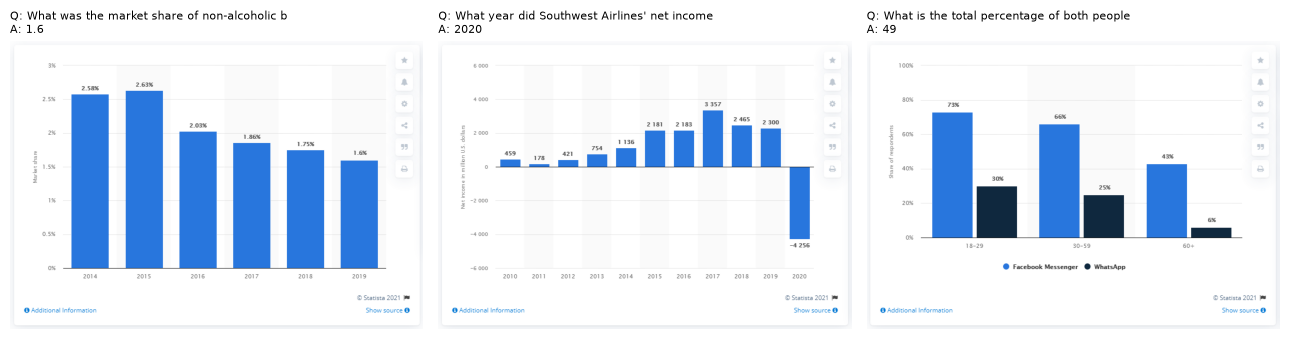

In [5]:
def load_chartqa(split: str, n: int, seed: int = 0) -> list[dict]:
    """Real (chart, question, answer) triples from the Hub."""
    ds = load_dataset(DATASET_NAME, split=split).shuffle(seed=seed).select(range(n))
    return [
        {
            "image": r["image"].convert("RGB"),
            "question": r["query"],
            "answer": r["label"][0],
        }
        for r in ds
    ]


TRAIN_SAMPLES = load_chartqa("train", 256)
# held out — never trained on
VAL_SAMPLES = load_chartqa("val", 64)
print(f"train {len(TRAIN_SAMPLES)}   val {len(VAL_SAMPLES)}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, s in zip(axes, VAL_SAMPLES[:3]):
    ax.imshow(s["image"])
    ax.axis("off")
    ax.set_title(f"Q: {s['question'][:44]}\nA: {s['answer']}", fontsize=8, loc="left")
plt.tight_layout()
plt.show()

## 1.2 From pixels to embeddings

```
image (800x557)
  ├─ processor ───────► pixel_values (1, 1, 3, 512, 512)
  │                     input_ids    (105,)  containing 64 <image> slots
  ├─ vision_model ────► (1, 1024, 768)     32x32 SigLIP patches (vison encoder raw output)
  ├─ pixel_shuffle ───► (1,   64, 12288)   4x4 patches folded into channels
  ├─ modality_proj ───► (1,   64, 960)     LLM embedding width
  └─ inputs_merger ───► inputs_embeds (1, 105, 960)
```

`<image>` is a real vocabulary entry (id `49190`), not a template variable. The processor
repeats it 64 times per tile and wraps the block in ordinary text tokens
`<fake_token_around_image>` as a delimiter and `<global-img>` to say which view this is. Those
markers are how the LLM learns *where* the image sits, and with tiling on it also
gets a `<row_i_col_j>` token before every tile. That is the entire spatial signal available
here: SmolVLM inherits SmolLM2's 1-D RoPE and has no mRoPE to encode a patch grid.

In [6]:
sample = VAL_SAMPLES[0]
enc = processor(
    text=[prompt_text(sample["question"])],
    images=[[sample["image"]]],
    return_tensors="pt",
)

ids = enc["input_ids"][0]
slots = ids == IMAGE_TOKEN_ID
first, last = int(slots.nonzero()[0]), int(slots.nonzero()[-1])

print(f"PIL image {sample['image'].size} ->")
for k, v in enc.items():
    print(f"  {k:<22} {tuple(v.shape)}")

print(
    f"\n{int(slots.sum())} <image> slots inside {ids.shape[0]} tokens, contiguous "
    f"from {first} to {last}"
)
print(f"  startswith:  {processor.tokenizer.decode(ids[first - 2:first + 2])!r}")
print(f"  endswith:  {processor.tokenizer.decode(ids[last - 1:last + 3])!r}")

PIL image (800, 557) ->
  input_ids              (1, 105)
  attention_mask         (1, 105)
  pixel_values           (1, 1, 3, 512, 512)
  pixel_attention_mask   (1, 1, 512, 512)

64 <image> slots inside 105 tokens, contiguous from 5 to 68
  startswith:  '<fake_token_around_image><global-img><image><image>'
  endswith:  '<image><image><fake_token_around_image>What'


Two things worth noticing:
1. The 64 vectors are *not* raw pixel crops: they leave the SigLIP transformer already
   contextualised over the whole tile, so a "visual token" is a learned summary of a region.
2. The whole connector is one bias-free matrix whose input width, `12288 = 768 × 4²`, is the
   pixel shuffle: each token concatenates a 4 × 4 block of patches, so the 64 tokens tile a
   512 px tile as an 8 × 8 grid and one token spans 64 × 64 pixels, wider than most axis labels
   on a chart.

In [7]:
# vision_model + connector + text_model
vlm = model.model
# 16 px
PATCH = model.config.vision_config.patch_size
# pixel-shuffle fold factor, 4
SCALE = vlm.connector.scale_factor
# 32 patches per side
GRID = 512 // PATCH

tiles = enc["pixel_values"].to(DEVICE)
pam = enc["pixel_attention_mask"].to(DEVICE)

with torch.no_grad():
    # collapse (batch, tiles) into one image batch, exactly as get_image_features does
    flat = tiles.view(-1, *tiles.shape[2:])
    patch_mask = pam.view(-1, *pam.shape[2:])
    patch_mask = (
        patch_mask.unfold(1, PATCH, PATCH).unfold(2, PATCH, PATCH).sum((-1, -2)) > 0
    )

    patches = vlm.vision_model(
        pixel_values=flat, patch_attention_mask=patch_mask
    ).last_hidden_state
    folded = vlm.connector.pixel_shuffle(patches, SCALE)
    visual = vlm.connector.modality_projection(folded)
    official = vlm.get_image_features(tiles, pam).pooler_output

print(f"pixel_values      {tuple(flat.shape)}")
print(
    f"  vision_model  ->{tuple(patches.shape)}   {GRID}x{GRID} patches x "
    f"{patches.shape[-1]}d"
)
print(
    f"  pixel_shuffle ->{tuple(folded.shape)}   {SCALE}x{SCALE} patches folded into "
    "channels"
)
print(f"  projection    ->{tuple(visual.shape)}   LLM embedding width")

proj = vlm.connector.modality_projection.proj
print(
    f"\nthe whole connector is one {tuple(proj.weight.shape)} matrix "
    f"({proj.weight.numel() / 1e6:.1f}M params, no bias)"
)
print(
    f"matches model.get_image_features : {torch.allclose(visual, official, atol=1e-4)}"
)

pixel_values      (1, 3, 512, 512)
  vision_model  ->(1, 1024, 768)   32x32 patches x 768d
  pixel_shuffle ->(1, 64, 12288)   4x4 patches folded into channels
  projection    ->(1, 64, 960)   LLM embedding width

the whole connector is one (960, 12288) matrix (11.8M params, no bias)
matches model.get_image_features : True


`inputs_merger` embeds the *whole* `input_ids` tensor first — `<image>` ids included — and then
overwrites those rows with the connector output, in order: the n-th run of 64 slots receives
tile n. The `<image>` row of the embedding table is looked up on every forward pass and thrown
away every time, which the norms below make obvious.

In [8]:
input_ids = ids.unsqueeze(0).to(DEVICE)
with torch.no_grad():
    text_embeds = model.get_input_embeddings()(input_ids)
    merged = vlm.inputs_merger(input_ids, text_embeds, visual)

mask = slots.to(DEVICE)
print(f"embedding lookup over all {ids.shape[0]} ids  {tuple(text_embeds.shape)}")
print(f"after inputs_merger                  {tuple(merged.shape)}\n")
same = torch.allclose(merged[0][mask], visual.reshape(-1, visual.shape[-1]), atol=1e-5)
print(f"slots now hold the connector output  {same}")
print(
    "text rows untouched                  "
    f"{torch.allclose(merged[0][~mask], text_embeds[0][~mask])}"
)

row = model.get_input_embeddings().weight[IMAGE_TOKEN_ID].detach()
print(
    f"\n<image> row in the embedding table   ||v|| = {row.norm():6.2f}  (looked up, "
    "then discarded)"
)
print(f"what the slot actually carries       ||v|| = {merged[0][mask][0].norm():6.2f}")

embedding lookup over all 105 ids  (1, 105, 960)
after inputs_merger                  (1, 105, 960)

slots now hold the connector output  True
text rows untouched                  True

<image> row in the embedding table   ||v|| =   0.74  (looked up, then discarded)
what the slot actually carries       ||v|| = 145.11


## 1.3 Loss masking

Same principle as text SFT , supervise only the assistant span but with two extra rules that
exist only because there is an image:

1. **Image placeholders must be masked.** They are inputs, never targets. If they leak into the
   labels the model is trained to *emit* `<image>` tokens, which corrupts generation outright.
2. **Padding side flips between phases.** Training pads right (labels stay aligned with the
   prompt prefix); batched generation pads **left** (otherwise the model continues from pad
   tokens and produces garbage).

```
Input:  [{image, question, answer}, ...]
Output: input_ids (batch, seq)  pixel_values (batch, tiles, 3, 512, 512)
        attention_mask (batch, seq)  labels (batch, seq) with -100 everywhere but the answer
```

In [9]:
def collate(batch: list[dict]) -> dict[str, torch.Tensor]:
    """Tokenize + tile a batch and build the supervised-answer label mask."""
    processor.tokenizer.padding_side = "right"
    texts = [full_text(b["question"], b["answer"]) for b in batch]
    enc = processor(
        text=texts,
        images=[[b["image"]] for b in batch],
        return_tensors="pt",
        padding=True,
    )

    # Prompt length per sample, measured after image expansion
    prompt_lens = [
        len(
            processor(text=[prompt_text(b["question"])], images=[[b["image"]]])[
                "input_ids"
            ][0]
        )
        for b in batch
    ]

    labels = enc["input_ids"].clone()
    # padding
    labels[enc["attention_mask"] == 0] = IGNORE_INDEX
    # visual placeholders
    labels[labels == IMAGE_TOKEN_ID] = IGNORE_INDEX
    # system + question
    for i, n in enumerate(prompt_lens):
        labels[i, :n] = IGNORE_INDEX

    enc["labels"] = labels
    return enc


train_loader = DataLoader(TRAIN_SAMPLES, batch_size=2, shuffle=True, collate_fn=collate)

batch = next(iter(train_loader))
print("batch tensors:")
for k, v in batch.items():
    print(f"  {k:>15}: {tuple(v.shape)}")

ids, labels = batch["input_ids"][0], batch["labels"][0]
n_img = int((ids == IMAGE_TOKEN_ID).sum())
n_sup = int((labels != IGNORE_INDEX).sum())
print(
    f"\nsequence      : {ids.shape[0]} tokens = {n_img} visual + "
    f"{ids.shape[0] - n_img} text"
)
print(f"supervised    : {n_sup} tokens ({n_sup / ids.shape[0]:.1%} of the sequence)")
print(f"target        : {processor.tokenizer.decode(labels[labels != IGNORE_INDEX])!r}")

batch tensors:
        input_ids: (2, 118)
   attention_mask: (2, 118)
     pixel_values: (2, 1, 3, 512, 512)
  pixel_attention_mask: (2, 1, 512, 512)
           labels: (2, 118)

sequence      : 118 tokens = 64 visual + 54 text
supervised    : 5 tokens (4.2% of the sequence)
target        : ' 163<end_of_utterance>'


## 1.4 Performance Metric

**Relaxed accuracy** is ChartQA's official metric: exact string match after normalisation, or —
for numeric answers — within 5% of the gold value. We report strict match alongside it, because
a large relaxed-vs-strict gap is itself a finding: it means the model knows the answer but not
the *format*, which is exactly what instruction tuning fixes cheaply.

In [10]:
def normalize(s: str) -> str:
    """Lower-case and drop whitespace, %, $ and commas."""
    return re.sub(r"[\s%$,]", "", s.strip().lower().rstrip(".").strip())


def relaxed_match(pred: str, gold: str, tol: float = 0.05) -> bool:
    """ChartQA relaxed accuracy: string match, or numeric match within 5%."""
    p, g = normalize(pred), normalize(gold)
    if p == g:
        return True
    try:
        pn = float(re.sub(r"[^0-9.\-]", "", p)) if re.search(r"\d", p) else None
        gn = float(re.sub(r"[^0-9.\-]", "", g)) if re.search(r"\d", g) else None
    except ValueError:
        return False
    return pn is not None and gn is not None and abs(pn - gn) <= tol * abs(gn)

In [11]:
@torch.no_grad()
@torch.no_grad()
def generate_answers(
    model: nn.Module,
    samples: list[dict],
    images: list | None = None,
    batch_num: int = 4,
    max_new_tokens: int = 12,
) -> list[str]:
    """Greedy short answers for a list of samples, batched with left padding."""

    # generation: pad on the left
    processor.tokenizer.padding_side = "left"
    model.eval()
    images = images if images is not None else [s["image"] for s in samples]
    preds = []
    for i in range(0, len(samples), batch_num):
        chunk, imgs = samples[i : i + batch_num], images[i : i + batch_num]
        enc = processor(
            text=[prompt_text(s["question"]) for s in chunk],
            images=[[im] for im in imgs],
            return_tensors="pt",
            padding=True,
        ).to(DEVICE)

        out = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
        preds += [
            p.strip()
            for p in processor.batch_decode(
                out[:, enc["input_ids"].shape[1] :], skip_special_tokens=True
            )
        ]
    return preds


def evaluate(
    model: nn.Module,
    samples: list[dict],
    images: list | None = None,
    batch_num: int = 4,
    show: int = 0,
    tag: str = "",
) -> dict:
    """Relaxed and strict ChartQA accuracy, optionally printing the first `show`."""

    preds = generate_answers(model, samples, images, batch_num=batch_num)
    relaxed = [relaxed_match(p, s["answer"]) for p, s in zip(preds, samples)]
    strict = [normalize(p) == normalize(s["answer"]) for p, s in zip(preds, samples)]
    result = {
        "relaxed": sum(relaxed) / len(relaxed),
        "strict": sum(strict) / len(strict),
        "preds": preds,
    }

    if tag:
        print(
            f"{tag:<22} relaxed {result['relaxed']:6.1%}   strict "
            f"{result['strict']:6.1%}"
        )
    for i in range(show):
        print(
            f"   {'OK ' if relaxed[i] else ' X '} pred={preds[i][:34]!r:38s} "
            f"gold={samples[i]['answer']!r}"
        )
    return result

In [12]:
t0 = time.time()
base = evaluate(model, VAL_SAMPLES, show=5, tag="base checkpoint")
print(f"\n({time.time() - t0:.0f}s for {len(VAL_SAMPLES)} samples)")

base checkpoint        relaxed  39.1%   strict  20.3%
   OK  pred='1.6%.'                                gold='1.6'
   OK  pred='2019.'                                gold='2020'
    X  pred='114.'                                 gold='49'
    X  pred='5.1.'                                 gold='2.8'
    X  pred='Lake Maggiore.'                       gold='Lago Maggiore'

(18s for 64 samples)


## 1.5 Resolution

The knob with no text-side analogue. A VLM reads a chart through a fixed grid of visual tokens;
if the axis labels fall below that grid's resolution, no amount of instruction tuning will
recover them — the information is gone before the LLM sees anything.

Modern VLMs handle this with **tiling** (SmolVLM/Idefics3), **native dynamic resolution**
(Qwen2-VL), or **multi-crop** (LLaVA-NeXT): the image is cut into tiles, each tile is encoded
separately, and a downscaled "global" view is appended. Cost is linear in tiles and the
sequence the LLM attends over grows with it.

```
longest_edge=512   → 1 tile         →  64 visual tokens   (cheap, blurry axis labels)
longest_edge=1024  → 4 tiles + global → 320 visual tokens
longest_edge=1536  → 9 tiles + global → 640 visual tokens  (readable labels, ~10x the vision compute)
```

Tile counts depend on the image's aspect ratio, so the exact numbers vary per chart — the cell
below measures them rather than assuming.

We sweep it on the **untuned** checkpoint, so the effect is pure input resolution, not training.

longest_edge=512     64 visual tokens   relaxed  39.1%   strict  20.3%      18s


longest_edge=1024   320 visual tokens   relaxed  59.4%   strict  53.1%      81s


longest_edge=1536   640 visual tokens   relaxed  48.4%   strict  45.3%     120s


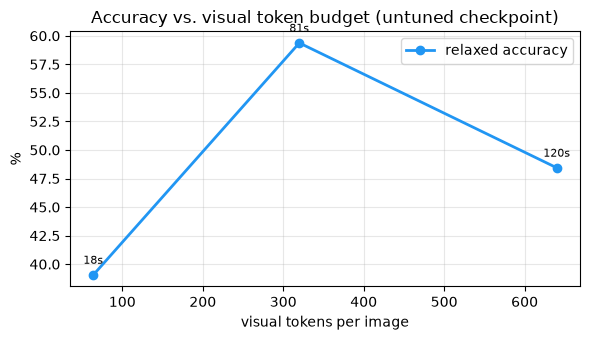

In [13]:
def set_resolution(longest_edge: int, split: bool = True) -> None:
    """Tiling policy: resize so the long side is `longest_edge`, then cut into
    512-pixel tiles (+ one global thumbnail) when `split` is on."""
    processor.image_processor.do_image_splitting = split
    processor.image_processor.size = {"longest_edge": longest_edge}


def visual_tokens_per_image(sample: dict) -> int:
    """Number of <image> placeholders the processor emits for one sample."""
    enc = processor(
        text=[prompt_text(sample["question"])],
        images=[[sample["image"]]],
        return_tensors="pt",
    )
    return int((enc["input_ids"] == IMAGE_TOKEN_ID).sum())


# (edge, split, eval batch)
RESOLUTIONS = [(512, False, 4), (1024, True, 2), (1536, True, 1)]
res_rows = []
for edge, split, bs in RESOLUTIONS:
    set_resolution(edge, split)
    n_tok = visual_tokens_per_image(VAL_SAMPLES[0])
    t0 = time.time()
    r = evaluate(model, VAL_SAMPLES, batch_num=bs)
    res_rows.append(
        {
            "edge": edge,
            "tokens": n_tok,
            "relaxed": r["relaxed"],
            "strict": r["strict"],
            "sec": time.time() - t0,
        }
    )
    print(
        f"longest_edge={edge:<5} {n_tok:>4} visual tokens   "
        f"relaxed {r['relaxed']:6.1%}   strict {r['strict']:6.1%}   "
        f"{res_rows[-1]['sec']:5.0f}s"
    )

# back to the cheap setting for training
set_resolution(512, False)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(
    [r["tokens"] for r in res_rows],
    [r["relaxed"] * 100 for r in res_rows],
    "o-",
    color="#2196F3",
    linewidth=2,
    label="relaxed accuracy",
)
for r in res_rows:
    ax.annotate(
        f"{r['sec']:.0f}s",
        (r["tokens"], r["relaxed"] * 100),
        textcoords="offset points",
        xytext=(0, 8),
        fontsize=8,
        ha="center",
    )
ax.set_xlabel("visual tokens per image")
ax.set_ylabel("%")
ax.set_title("Accuracy vs. visual token budget (untuned checkpoint)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# 2) LoRA Instruction tuning

Nothing multimodal about the optimiser — the only VLM-specific choices are that the vision
tower runs in the forward pass every step (so batch size is bound by *tiles*, not by text
tokens), and that the connector, when unfrozen, is trained **full-rank** and therefore needs an
LR about 10× *below* the LoRA adapters. LoRA tolerates 1e-4 because its update starts at zero
and is rank-limited; the same LR applied to 11.8M dense connector weights walks the vision–text
alignment off a cliff in a few dozen steps.

Budget here is deliberately tiny (256 examples, 2 epochs, and the cheap 64-token tiling) so the
run takes minutes. That is a deliberate trade, not a recommendation: the resolution sweep above
showed that the same checkpoint reads charts far better at 320 visual tokens, and a real run would train
*at the resolution it will be served at* — 5x the step cost, and the starting point is the higher
curve rather than the lower one.

So expect *format* to be learned fully and *chart reading* to move very little. The evaluation below measures
exactly that split, and it is the honest shape of a few-hundred-example Stage 2 run.

In [14]:
TEXT_ATTN = r".*text_model.*(q_proj|k_proj|v_proj|o_proj)$"


def add_lora(
    model: nn.Module,
    target_regex: str = TEXT_ATTN,
    rank: int = 16,
    alpha: int = 32,
    train_connector: bool = False,
) -> nn.Module:
    """Attach LoRA to the language model only, optionally unfreezing the connector."""
    model = get_peft_model(
        model,
        LoraConfig(
            r=rank, lora_alpha=alpha, lora_dropout=0.05, target_modules=target_regex
        ),
    )
    if train_connector:
        for p in model.base_model.model.model.connector.parameters():
            p.requires_grad = True
    return model


def trainable_report(model: nn.Module) -> None:
    """Trainable parameter counts per part of the VLM."""
    total = sum(p.numel() for p in model.parameters())
    groups: dict[str, int] = {}
    for name, p in model.named_parameters():
        if p.requires_grad:
            part = (
                "vision"
                if "vision_model" in name
                else (
                    "connector"
                    if "connector" in name
                    else "text_model" if "text_model" in name else "other"
                )
            )
            groups[part] = groups.get(part, 0) + p.numel()
    trainable = sum(groups.values())
    print(f"trainable {trainable:,} / {total:,} ({trainable / total:.2%})")
    for k, v in sorted(groups.items()):
        print(f"  {k:<12} {v:>10,}")


model = add_lora(model)
trainable_report(model)

trainable 3,276,800 / 510,759,104 (0.64%)
  text_model    3,276,800


In [15]:
@dataclass
class TrainConfig:
    epochs: int = 2
    lora_lr: float = 1e-4
    connector_lr: float = 1e-5
    weight_decay: float = 0.01
    warmup_ratio: float = 0.1
    max_grad_norm: float = 1.0


def train(
    model: nn.Module,
    loader: DataLoader,
    cfg: TrainConfig = TrainConfig(),
    log_every: int = 40,
) -> list[float]:
    """LoRA (and optional connector) training with warmup + cosine; returns losses."""
    lora_params = [
        p for n, p in model.named_parameters() if p.requires_grad and "lora_" in n
    ]
    conn_params = [
        p for n, p in model.named_parameters() if p.requires_grad and "connector" in n
    ]
    groups = [{"params": lora_params, "lr": cfg.lora_lr}]
    if conn_params:
        groups.append({"params": conn_params, "lr": cfg.connector_lr})
    opt = torch.optim.AdamW(groups, weight_decay=cfg.weight_decay)

    total = max(len(loader) * cfg.epochs, 1)
    warm = max(int(total * cfg.warmup_ratio), 1)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt,
        lambda s: (
            s / warm
            if s < warm
            else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(total - warm, 1)))
        ),
    )

    history, t0 = [], time.time()
    model.train()
    for epoch in range(cfg.epochs):
        for step, batch in enumerate(loader):
            out = model(**{k: v.to(DEVICE) for k, v in batch.items()})
            out.loss.backward()
            torch.nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad], cfg.max_grad_norm
            )
            opt.step()
            sched.step()
            opt.zero_grad()
            history.append(out.loss.item())
            if log_every and len(history) % log_every == 0:
                print(
                    f"  step {len(history):>4}/{total}  loss "
                    f"{sum(history[-log_every:]) / log_every:.4f}"
                    f"  {time.time() - t0:5.0f}s"
                )
    print(f"trained {len(history)} steps in {time.time() - t0:.0f}s")
    return history


loss_history = train(model, train_loader)

  step   40/256  loss 2.3297     27s


  step   80/256  loss 0.9152     54s


  step  120/256  loss 0.9291     81s


  step  160/256  loss 0.7561    108s


  step  200/256  loss 0.7058    135s


  step  240/256  loss 0.6662    162s


trained 256 steps in 173s


after LoRA SFT         relaxed  39.1%   strict  26.6%
   OK  pred='1.6'                                  gold='1.6'
   OK  pred='2019'                                 gold='2020'
    X  pred='100'                                  gold='49'
    X  pred='5.3'                                  gold='2.8'
    X  pred='Lago di Voi'                          gold='Lago Maggiore'

relaxed 39.1% → 39.1%    strict 20.3% → 26.6%


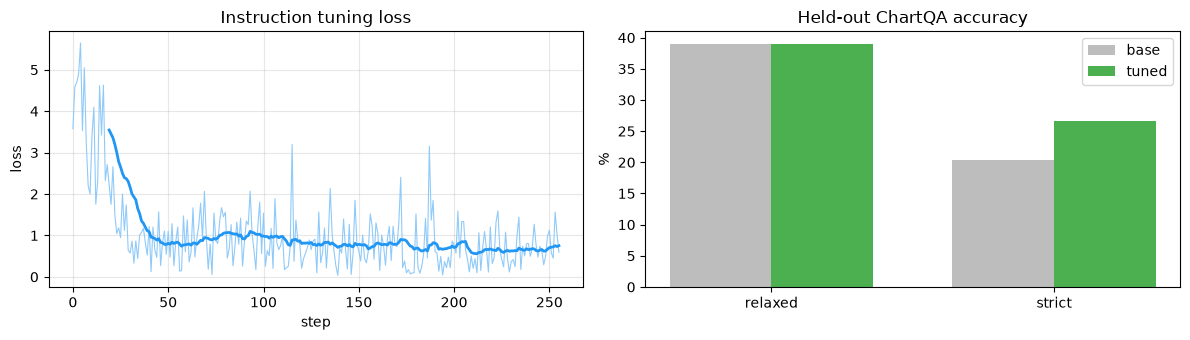

In [16]:
tuned = evaluate(model, VAL_SAMPLES, show=5, tag="after LoRA SFT")
print(
    f"\nrelaxed {base['relaxed']:.1%} → {tuned['relaxed']:.1%}"
    f"    strict {base['strict']:.1%} → {tuned['strict']:.1%}"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(loss_history, linewidth=0.8, color="#90CAF9")
if len(loss_history) >= 20:
    smooth = torch.tensor(loss_history).unfold(0, 20, 1).mean(1)
    axes[0].plot(range(19, len(loss_history)), smooth, color="#2196F3", linewidth=2)
axes[0].set_xlabel("step")
axes[0].set_ylabel("loss")
axes[0].set_title("Instruction tuning loss")
axes[0].grid(alpha=0.3)

x = torch.arange(2).numpy()
axes[1].bar(
    x - 0.18,
    [base["relaxed"] * 100, base["strict"] * 100],
    0.36,
    label="base",
    color="#BDBDBD",
)
axes[1].bar(
    x + 0.18,
    [tuned["relaxed"] * 100, tuned["strict"] * 100],
    0.36,
    label="tuned",
    color="#4CAF50",
)
axes[1].set_xticks(x)
axes[1].set_xticklabels(["relaxed", "strict"])
axes[1].set_ylabel("%")
axes[1].set_title("Held-out ChartQA accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()